# 主要駅（中心地）の選び方（PR #19・Issue #10）

PR #19 では、東京・新宿・渋谷・品川・六本木・虎ノ門の 6 駅までの距離を特徴量にした。この 6 駅は、価格を見ずに「大きなオフィス街」という理由で選んだ候補（Issue #10 の候補 3）。

このノートブックでは、**6 駅だけで足りているか、足すならどこか**を、地区の価格の集計とクラスタリングで調べる。モデルの精度はここでは測らない（CV で比べるのは PR の流れで行う）。

進め方:

1. 地区ごとの「価格の水準」を作る（`fujise_detail.ipynb` の Q12・Q13 と同じ作り方）
2. 価格の水準を、6 駅までの距離で説明する。説明できずに残った分（残り）を地図で見る
3. 残りが大きい地区をクラスタリングして、どこに固まっているかを調べる
4. 期間を 2023 年第 1 四半期までに区切っても、同じ場所が出るかを確かめる
5. 見つかった場所を、価格を見ずに決められる言い方（乗降客数など）で表せるかを確かめる

**使うデータ**: train の全期間。検証期間（2023 年第 2 四半期以降）の価格も見ているので、4 で、検証期間より前のデータだけでも同じ結果になるかを確かめる。

In [1]:
import io
import json
import unicodedata
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib_fontja  # グラフで日本語を表示する
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans

TARGET = "取引価格（総額）"

train = pd.read_csv("../utokyo-mlapp-2026-ex1/train.csv", dtype={"面積（㎡）": str})
train["面積_数値"] = pd.to_numeric(train["面積（㎡）"].str.replace("2,000㎡以上", "2000"))
train["建築年_数値"] = pd.to_numeric(train["建築年"].str.extract(r"(\d{4})年")[0])
period = train["取引時期"].str.extract(r"(\d{4})年第(\d)四半期").astype(int)
train["時期_数値"] = period[0] + (period[1] - 1) / 4
train["㎡単価"] = train[TARGET] / train["面積_数値"]
train["面積帯"] = pd.cut(train["面積_数値"], [0, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 90, 100, 2000])
train["建築年帯"] = pd.cut(train["建築年_数値"], [1900, 1970, 1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2030])
train["地区"] = train["市区町村名"] + "・" + train["地区名"]

## 外部データ

どちらも取引データではなく、基準日は 2025 年第 2 四半期より前（AGENTS.md の規約を満たす）。`../external_data/` になければダウンロードする。

- 地区の緯度・経度: 「大字・町丁目レベル位置参照情報 国土交通省」（2023 年版（17.0b）、東京都、ファイル名 `13000-17.0b.zip`、https://nlftp.mlit.go.jp/isj/ ）を加工して作成。丁目を外して町名ごとに緯度・経度を平均した（PR #19 の `src/features/district_latlon.py` と同じ）
- 駅の位置と乗降客数: 「国土数値情報（駅別乗降客数データ）」（国土交通省）（2024 年度版、S12-25）を加工して作成。利用規約: https://nlftp.mlit.go.jp/ksj/other/agreement.html 。駅ごとに、会社ごとの乗降客数（2024 年度）を足した（`fujise_detail.ipynb` の Q14 と同じ）

In [2]:
EXTERNAL = Path("../external_data")
ISJ_ZIP = EXTERNAL / "13000-17.0b.zip"
S12_ZIP = EXTERNAL / "S12-25_GML.zip"
for url, path in [
    ("https://nlftp.mlit.go.jp/isj/dls/data/17.0b/13000-17.0b.zip", ISJ_ZIP),
    ("https://nlftp.mlit.go.jp/ksj/gml/data/S12/S12-25/S12-25_GML.zip", S12_ZIP),
]:
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, path)

with zipfile.ZipFile(ISJ_ZIP) as z:
    towns = pd.read_csv(io.BytesIO(z.read(next(n for n in z.namelist() if n.endswith(".csv")))), encoding="cp932")
towns["町名"] = towns["大字町丁目名"].str.replace(r"[一二三四五六七八九十]+丁目$", "", regex=True)
town_points = towns.groupby(["市区町村名", "町名"])[["緯度", "経度"]].mean()
latlon = town_points.reindex(pd.MultiIndex.from_frame(train[["市区町村名", "地区名"]]))
train["緯度"] = latlon["緯度"].to_numpy()
train["経度"] = latlon["経度"].to_numpy()


def normalize_station(name):
    """駅名の表記ゆれ（異体字、「ケ」と「ヶ」）をそろえる。"""
    return unicodedata.normalize("NFKC", name).replace("ケ", "ヶ")


with zipfile.ZipFile(S12_ZIP) as z:
    features = json.load(z.open("S12-25_GML/UTF-8/S12-25_NumberOfPassengers.geojson"))["features"]
lines = pd.DataFrame(
    [
        {
            "駅名": normalize_station(f["properties"]["S12_001"]),
            "駅コード": f["properties"]["S12_001g"],
            "会社": f["properties"]["S12_002"],
            "緯度": np.mean([c[1] for c in f["geometry"]["coordinates"]]),
            "経度": np.mean([c[0] for c in f["geometry"]["coordinates"]]),
            "乗降客数": f["properties"]["S12_061"] or 0,
        }
        for f in features
    ]
)
lines = lines[lines["緯度"].between(35.3, 36.1) & lines["経度"].between(138.8, 140.3)]
stations = lines.groupby(["駅名", "駅コード"])[["緯度", "経度"]].mean()
# 乗り換え駅は路線ごとに行があり、同じ会社の路線では乗降客数が 1 行にだけ入っているので、会社ごとに最大値を取ってから足す
stations["乗降客数"] = lines.groupby(["駅名", "駅コード", "会社"])["乗降客数"].max().groupby(["駅名", "駅コード"]).sum()
stations = stations.reset_index()
print(f"緯度・経度が付いた行: {train['緯度'].notna().mean():.3%} / 駅: {len(stations)}")

緯度・経度が付いた行: 99.999% / 駅: 1420


## 1. 地区ごとの価格の水準

log(㎡単価) から、取引時期・面積帯・建築年帯の効果を取り除き（`fujise_detail.ipynb` の Q12 の `remove_effects`）、地区ごとに平均する。件数が 30 件以上の地区だけを使う。

距離は、PR #19 と同じくハバーサインの公式で計算する。

In [3]:
CENTERS = {  # PR #19 の 6 駅（src/features/major_station.py の STATION_POINTS）
    "東京": (35.681236, 139.767125),
    "新宿": (35.689796, 139.699930),
    "渋谷": (35.658977, 139.701647),
    "品川": (35.632106, 139.737307),
    "六本木": (35.660329, 139.730276),
    "虎ノ門": (35.668580, 139.749508),
}
KM_PER_DEG = 111.0
COS_LAT = np.cos(np.radians(35.68))


def haversine_km(lat1, lon1, lat2, lon2):
    """2 点間の大圏距離（km）。"""
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((phi2 - phi1) / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def remove_effects(df, y, keys, n_iter=10):
    """y から keys の効果を交互に取り除いた残りを返す。"""
    effects = {k: pd.Series(0.0, index=y.index) for k in keys}
    for _ in range(n_iter):
        for k in keys:
            others = sum(v for kk, v in effects.items() if kk != k)
            effects[k] = (y - others).groupby(df[k].astype(str)).transform("mean")
    return y - sum(effects.values())


def district_levels(df, min_count=30):
    """地区ごとの価格の水準（時期・面積・建築年をそろえた log(㎡単価) の平均）。"""
    level = remove_effects(df, np.log(df["㎡単価"]), ["取引時期", "面積帯", "建築年帯"])
    rows = pd.DataFrame({"地区": df["地区"], "市区町村名": df["市区町村名"], "緯度": df["緯度"], "経度": df["経度"], "水準": level})
    table = rows.dropna().groupby("地区").agg(
        市区町村名=("市区町村名", "first"), 緯度=("緯度", "first"), 経度=("経度", "first"), 水準=("水準", "mean"), 件数=("水準", "size")
    )
    return table[table["件数"] >= min_count]


def weighted_fit(table, columns):
    """価格の水準を columns の直線の和で表す（件数で重みづけ）。当てはめた値と、説明できた割合を返す。"""
    x = np.column_stack(columns + [np.ones(len(table))])
    w = np.sqrt(table["件数"].to_numpy())
    beta, *_ = np.linalg.lstsq(x * w[:, None], table["水準"].to_numpy() * w, rcond=None)
    fit = x @ beta
    y, weight = table["水準"], table["件数"]
    r2 = 1 - np.average((y - fit) ** 2, weights=weight) / np.average((y - np.average(y, weights=weight)) ** 2, weights=weight)
    return pd.Series(fit, index=table.index), r2


def center_columns(table):
    """6 駅までの距離（log）の列。0 km で発散しないよう 0.5 km を足す。"""
    return [np.log(haversine_km(table["緯度"], table["経度"], lat, lon) + 0.5).to_numpy() for lat, lon in CENTERS.values()]


levels = district_levels(train)
fit6, r2_6 = weighted_fit(levels, center_columns(levels))
levels["残り"] = levels["水準"] - fit6
print(f"地区: {len(levels)}（取引 {levels['件数'].sum():,} 件）")
print(f"6 駅までの距離（log）で説明できる価格の水準のばらつき: {r2_6:.1%}")

地区: 994（取引 193,990 件）
6 駅までの距離（log）で説明できる価格の水準のばらつき: 82.2%


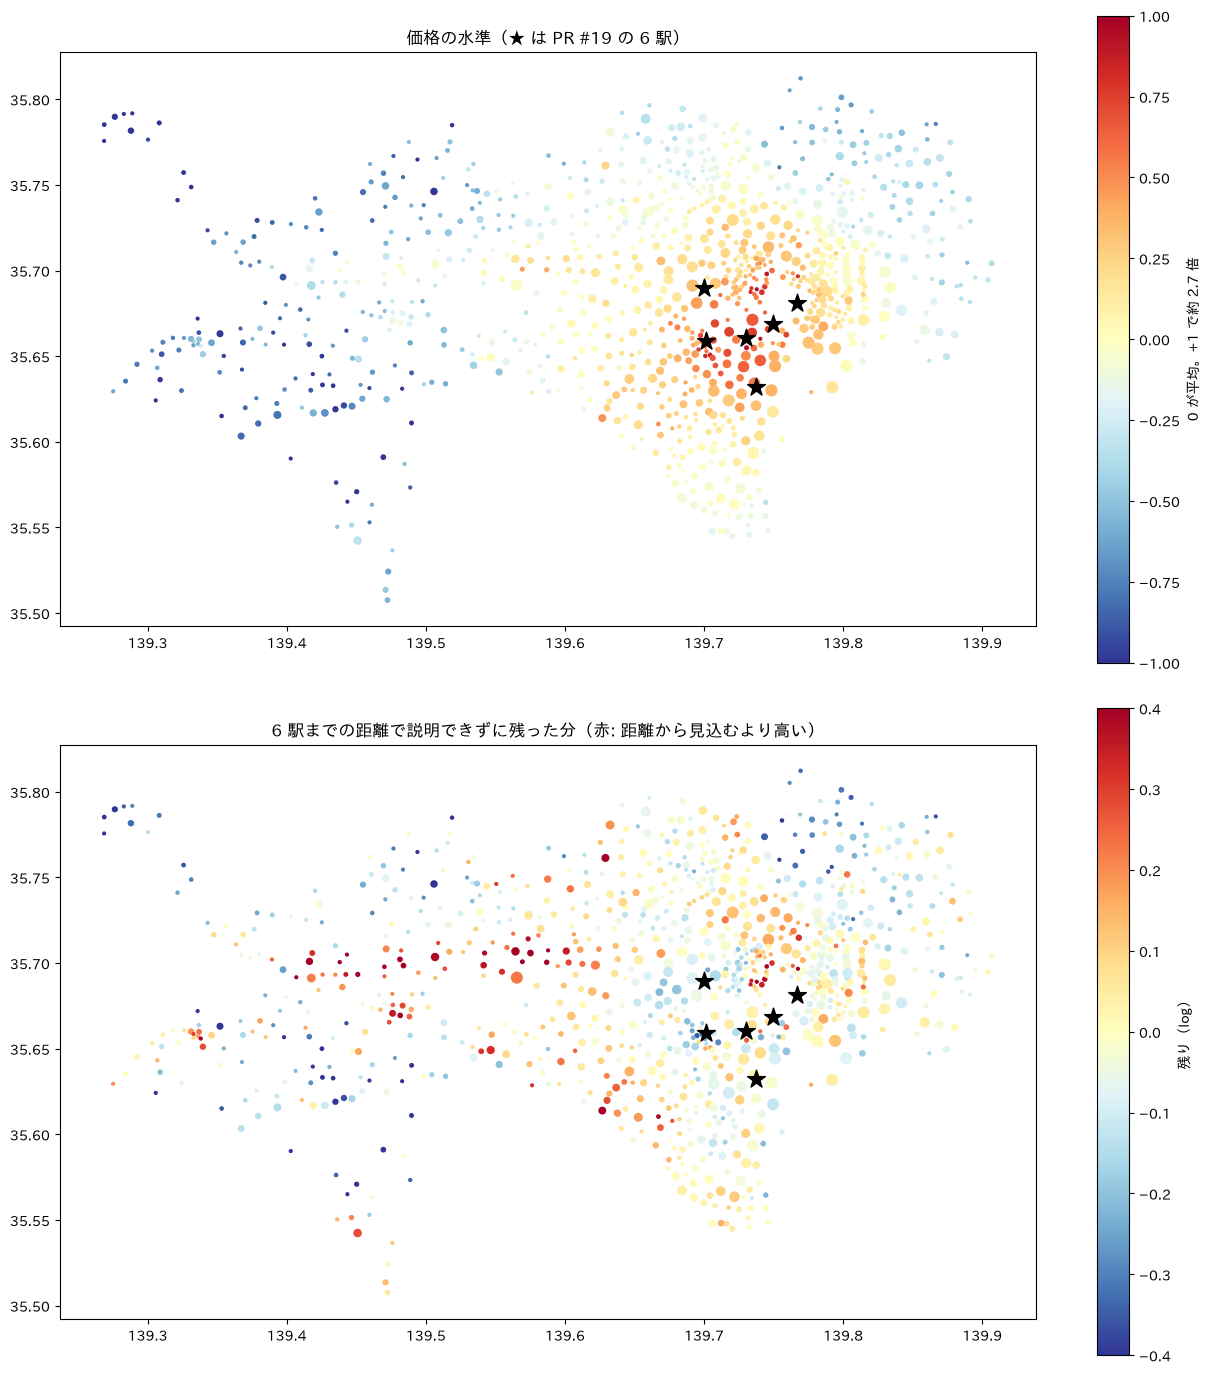

In [4]:
def draw_map(ax, table, values, title, vmax, cmap="RdYlBu_r"):
    """地区を地図上の点で描き、values で色を塗る。"""
    sc = ax.scatter(table["経度"], table["緯度"], c=values, s=np.clip(table["件数"] / 15, 4, 60), cmap=cmap, vmin=-vmax, vmax=vmax)
    for name, (lat, lon) in CENTERS.items():
        ax.scatter(lon, lat, marker="*", s=180, color="black")
    ax.set_aspect(1 / COS_LAT)
    ax.set_title(title)
    return sc


fig, axes = plt.subplots(2, 1, figsize=(13, 14))
sc = draw_map(axes[0], levels, levels["水準"], "価格の水準（★ は PR #19 の 6 駅）", vmax=1)
fig.colorbar(sc, ax=axes[0], label="0 が平均。+1 で約 2.7 倍")
sc = draw_map(axes[1], levels, levels["残り"], "6 駅までの距離で説明できずに残った分（赤: 距離から見込むより高い）", vmax=0.4)
fig.colorbar(sc, ax=axes[1], label="残り（log）")
plt.tight_layout()
plt.show()

- 6 駅までの距離だけで、地区の価格の水準のばらつきの約 8 割を説明できる。PR #19 の距離の列が効いたことと合う
- 残り（下の地図）で赤い点が固まっている場所が、「6 駅からの距離から見込むより高い」場所。多摩では、**吉祥寺から国分寺・立川へ東西に帯のように並ぶ**（JR 中央線に沿っている）。ほかに、世田谷区の南西（二子玉川・自由が丘あたり）と、千代田区の北西（番町）が目立つ
- 6 駅のすぐ近くは青い（見込むより安い）。距離の log の直線で当てはめたので、0 km 近くで見込みが高くなりすぎるため。ここは当てはめ方のくせで、6 駅の近くが実際に安いわけではない

## 2. 残りの大きい地区のクラスタリング（DBSCAN）

残りが上位 15% の地区だけを取り出し、DBSCAN で「近い地区どうし」をまとめる。

- DBSCAN は、ある距離（`eps`）より近い点どうしをつなげて塊にする方法。塊の数を先に決めなくてよく、どの塊にも入らない点（ノイズ）を外せる
- `eps` は 1.5 km（駅 1〜2 つ分）、塊の最小の地区数は 3 にした
- 塊ごとに、件数で重みづけした重心と、重心から 1.5 km 以内で乗降客数の多い駅を出す

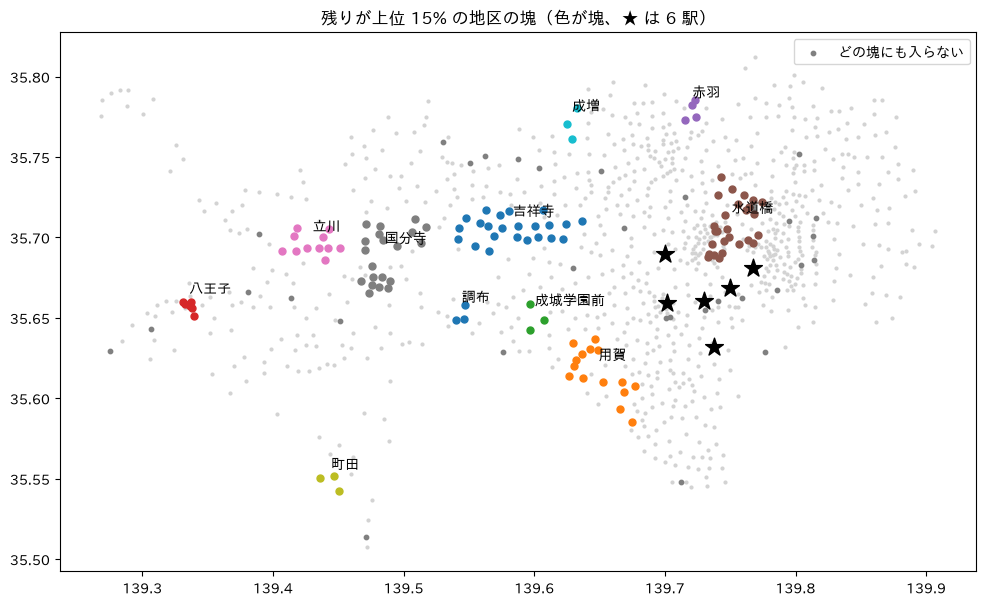

,地区数,取引件数,残りの平均,市区町村,近くの大きい駅（乗降客数）,残りが大きい地区
塊,,,,,,
5,27,4673,0.251,千代田区・文京区・新宿区,水道橋（18 万）・後楽園（10 万）,富士見・神田淡路町・四番町
0,23,4383,0.308,武蔵野市・杉並区・三鷹市,吉祥寺（38 万）・西荻窪（9 万）,御殿山・吉祥寺南町・吉祥寺本町
1,15,3484,0.237,世田谷区・大田区・目黒区,用賀（7 万）・尾山台（3 万）,玉川・自由が丘・瀬田
7,20,2603,0.288,府中市・国分寺市・小金井市,国分寺（31 万）,本町・南町・泉町
6,11,1530,0.356,国立市・立川市・国分寺市,立川（31 万）・立川北（4 万）,北・光町・曙町
9,3,889,0.267,練馬区・板橋区,成増（5 万）・地下鉄成増（5 万）,光が丘・成増・旭町
10,3,706,0.270,調布市,調布（12 万）・国領（3 万）,布田・小島町・調布ケ丘
4,4,680,0.174,北区,赤羽（19 万）・赤羽岩淵（9 万）,赤羽南・赤羽・岩淵町
3,6,665,0.280,八王子市,八王子（15 万）・京王八王子（5 万）,旭町・南町・子安町


In [5]:
def find_clusters(table, quantile=0.85, eps_km=1.5, min_samples=3):
    """残りが大きい地区を DBSCAN でまとめ、塊ごとの要約を返す。"""
    high = table[table["残り"] >= table["残り"].quantile(quantile)].copy()
    xy = np.c_[high["緯度"] * KM_PER_DEG, high["経度"] * KM_PER_DEG * COS_LAT]
    high["塊"] = DBSCAN(eps=eps_km, min_samples=min_samples).fit_predict(xy)
    summary = []
    for label, rows in high[high["塊"] >= 0].groupby("塊"):
        lat, lon = np.average(rows["緯度"], weights=rows["件数"]), np.average(rows["経度"], weights=rows["件数"])
        near = stations[haversine_km(stations["緯度"], stations["経度"], lat, lon) < 1.5].nlargest(2, "乗降客数")
        summary.append(
            {
                "塊": label,
                "地区数": len(rows),
                "取引件数": rows["件数"].sum(),
                "残りの平均": rows["残り"].mean(),
                "重心の緯度": lat,
                "重心の経度": lon,
                "市区町村": "・".join(rows["市区町村名"].value_counts().index[:3]),
                "近くの大きい駅（乗降客数）": "・".join(f"{n}（{p / 1e4:.0f} 万）" for n, p in zip(near["駅名"], near["乗降客数"])),
                "残りが大きい地区": "・".join(rows.nlargest(3, "残り").index.str.split("・").str[1]),
            }
        )
    return high, pd.DataFrame(summary).sort_values("取引件数", ascending=False).set_index("塊")


high, clusters_all = find_clusters(levels)

fig, ax = plt.subplots(figsize=(13, 7))
ax.scatter(levels["経度"], levels["緯度"], s=4, color="lightgray")
noise = high[high["塊"] < 0]
ax.scatter(noise["経度"], noise["緯度"], s=10, color="gray", label="どの塊にも入らない")
for label, rows in high[high["塊"] >= 0].groupby("塊"):
    ax.scatter(rows["経度"], rows["緯度"], s=25)
    ax.annotate(clusters_all.loc[label, "近くの大きい駅（乗降客数）"].split("（")[0], (rows["経度"].mean(), rows["緯度"].mean() + 0.008), fontsize=10)
for name, (lat, lon) in CENTERS.items():
    ax.scatter(lon, lat, marker="*", s=180, color="black")
ax.set_aspect(1 / COS_LAT)
ax.set_title("残りが上位 15% の地区の塊（色が塊、★ は 6 駅）")
ax.legend()
plt.show()
clusters_all.drop(columns=["重心の緯度", "重心の経度"]).style.format({"残りの平均": "{:.3f}"})

塊は大きく 2 種類に分かれる。

| 種類 | 塊 | 特徴 |
|---|---|---|
| **郊外の大きな駅のまわり** | 吉祥寺・国分寺・立川・八王子・町田・調布・赤羽・成増 | 塊の中心に、乗降客数の多い駅がある。6 駅から遠くても、大きな駅の近くは高い |
| **都心・城南の住宅地** | 千代田区の番町・神田、世田谷区の玉川（二子玉川）・目黒区の自由が丘、世田谷区の成城 | 中心に大きな駅がない。駅ではなく、住宅地としての評価で高い |

1 つ目は「大きな駅からの距離」で表せそう（4 で確かめる）。2 つ目は駅では表せず、`地区名` のカテゴリがすでに持っている情報と考えられる。

## 3. 地域分け（KMeans）

参考に、緯度・経度と価格の水準で KMeans をかけ、価格の似た地域がどう分かれるかを見る。距離（km）と価格の水準（log）は単位が違うので、それぞれ標準化してから使う。

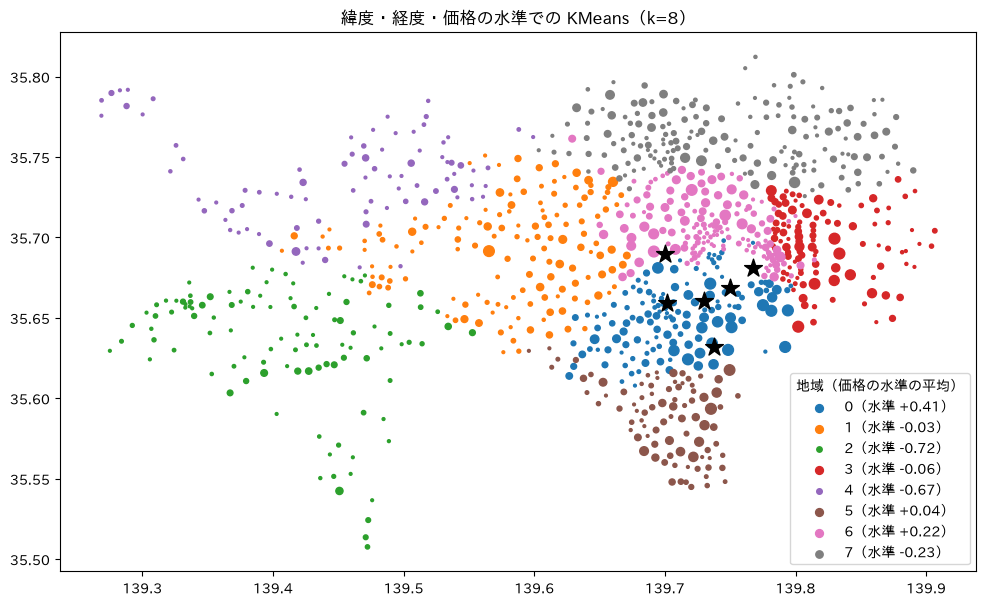

In [6]:
features_km = np.c_[levels["緯度"] * KM_PER_DEG, levels["経度"] * KM_PER_DEG * COS_LAT, levels["水準"]]
scaled = (features_km - features_km.mean(axis=0)) / features_km.std(axis=0)
levels["地域分け"] = KMeans(n_clusters=8, n_init=10, random_state=42).fit_predict(scaled, sample_weight=levels["件数"])

fig, ax = plt.subplots(figsize=(13, 7))
for label, rows in levels.groupby("地域分け"):
    ax.scatter(rows["経度"], rows["緯度"], s=np.clip(rows["件数"] / 15, 4, 60), label=f"{label}（水準 {np.average(rows['水準'], weights=rows['件数']):+.2f}）")
for name, (lat, lon) in CENTERS.items():
    ax.scatter(lon, lat, marker="*", s=180, color="black")
ax.set_aspect(1 / COS_LAT)
ax.set_title("緯度・経度・価格の水準での KMeans（k=8）")
ax.legend(title="地域（価格の水準の平均）")
plt.show()

- 一番高い地域（水準 +0.41）は、6 駅（★）を囲む都心から南西にまとまる。6 駅を中心地に選んだことと合う
- 多摩と 23 区の西側は、北（水準 −0.67）・**中央線沿い（−0.03）**・南（−0.72）の 3 つに分かれる。中央線沿いは、北や南より 0.6〜0.7（約 2 倍）高い。2 の地図で見た「中央線沿いの帯」と同じもの

## 4. 期間を区切っても同じ場所が出るか

全期間のデータには、CV の検証期間（2023 年第 2 四半期以降）の価格も入っている。検証期間より前（2023 年第 1 四半期まで）のデータだけで同じことをして、同じ塊が出るかを比べる。同じなら、検証期間の価格を見て中心地を選んだことにはならない。

In [7]:
early_levels = district_levels(train[train["時期_数値"] <= 2023.0])
fit_early, r2_early = weighted_fit(early_levels, center_columns(early_levels))
early_levels["残り"] = early_levels["水準"] - fit_early
_, clusters_early = find_clusters(early_levels)
print(f"2023 年第 1 四半期まで: 地区 {len(early_levels)}、6 駅で説明できる割合 {r2_early:.1%}（全期間 {r2_6:.1%}）")

# 全期間の塊ごとに、重心が一番近い 2023 年第 1 四半期までの塊を探す
matches = []
for label, row in clusters_all.iterrows():
    gap = haversine_km(clusters_early["重心の緯度"], clusters_early["重心の経度"], row["重心の緯度"], row["重心の経度"])
    matches.append(
        {
            "全期間の塊（市区町村）": row["市区町村"],
            "全期間の近くの駅": row["近くの大きい駅（乗降客数）"].split("（")[0],
            "2023Q1 までの近くの駅": clusters_early.loc[gap.idxmin(), "近くの大きい駅（乗降客数）"].split("（")[0],
            "重心のずれ_km": gap.min(),
        }
    )
pd.DataFrame(matches).style.format({"重心のずれ_km": "{:.1f}"})

2023 年第 1 四半期まで: 地区 844、6 駅で説明できる割合 80.3%（全期間 82.2%）


,全期間の塊（市区町村）,全期間の近くの駅,2023Q1 までの近くの駅,重心のずれ_km
0,千代田区・文京区・新宿区,水道橋,後楽園,0.1
1,武蔵野市・杉並区・三鷹市,吉祥寺,吉祥寺,0.3
2,世田谷区・大田区・目黒区,用賀,桜新町,0.1
3,府中市・国分寺市・小金井市,国分寺,国分寺,1.6
4,国立市・立川市・国分寺市,立川,立川,0.1
5,練馬区・板橋区,成増,光が丘,0.0
6,調布市,調布,成城学園前,4.6
7,北区,赤羽,赤羽,0.2
8,八王子市,八王子,八王子,0.1
9,町田市,町田,町田,0.0


2023 年第 1 四半期までのデータでも、ほぼ同じ場所に塊が出る。全期間の 11 の塊のうち 10 は、重心のずれが 1.6 km 以内の塊が見つかる（近くの駅の名前が違うのは、重心が数百 m ずれて、1.5 km 以内の一番大きい駅が入れ替わっただけ）。調布だけは、2023 年第 1 四半期までのデータでは塊にならなかった（一番近いのは 4.6 km 離れた成城の塊）。地区の価格の水準は年によってほとんど変わらないので、**全期間のデータで選んでも、検証期間の価格に合わせたことにはならない**と考えてよい。

## 5. 価格を見ずに決められる言い方で表せるか

2 で見つかった郊外の塊は、どれも乗降客数の多い駅のまわりにある。そこで「乗降客数が○万人以上の駅の中で、一番近い駅までの距離」を作り、6 駅で説明できずに残った分と比べる。この列は、駅の選び方に価格を使わない（乗降客数だけで決まる）。

In [8]:
is_ward = levels["市区町村名"].str.endswith("区")
rows = []
for threshold in [5, 10, 20, 30]:
    big = stations[stations["乗降客数"] >= threshold * 1e4]
    nearest = np.min([haversine_km(levels["緯度"], levels["経度"], lat, lon) for lat, lon in zip(big["緯度"], big["経度"])], axis=0)
    log_dist = np.log(nearest + 0.5)
    _, r2 = weighted_fit(levels, center_columns(levels) + [log_dist])
    rows.append(
        {
            "乗降客数": f"{threshold} 万人以上",
            "駅の数": len(big),
            "残りとの相関（全体）": np.corrcoef(log_dist, levels["残り"])[0, 1],
            "残りとの相関（23 区）": np.corrcoef(log_dist[is_ward], levels.loc[is_ward, "残り"])[0, 1],
            "残りとの相関（多摩）": np.corrcoef(log_dist[~is_ward], levels.loc[~is_ward, "残り"])[0, 1],
            "6 駅と合わせて説明できる割合": r2,
        }
    )
pd.DataFrame(rows).set_index("乗降客数").style.format("{:.2f}", subset=pd.IndexSlice[:, ["残りとの相関（全体）", "残りとの相関（23 区）", "残りとの相関（多摩）"]]).format(
    "{:.1%}", subset=["6 駅と合わせて説明できる割合"]
)

,駅の数,残りとの相関（全体）,残りとの相関（23 区）,残りとの相関（多摩）,6 駅と合わせて説明できる割合
乗降客数,,,,,
5 万人以上,321,-0.41,-0.30,-0.55,84.9%
10 万人以上,156,-0.38,-0.22,-0.61,84.9%
20 万人以上,66,-0.25,-0.09,-0.54,83.0%
30 万人以上,40,-0.24,-0.04,-0.53,82.7%


- **多摩では、大きな駅に近いほど、6 駅からの距離で見込むより高い**（相関 −0.5〜−0.6）。2 で見た「郊外の大きな駅のまわり」の塊を、この 1 列で表せる
- 23 区では効き方が弱い（−0.04〜−0.30）。23 区は 6 駅に近く、大きな駅も多いので、6 駅からの距離でほぼ説明できている
- しきい値は 5 万・10 万人でほぼ同じで、20 万人以上にすると弱くなる。20 万人以上の駅は多摩に少ない（国分寺・立川・町田などに限られる）ため

## まとめ

- PR #19 の 6 駅までの距離で、地区の価格の水準のばらつきの約 8 割を説明できる。一番高い地域は 6 駅のまわりにまとまっていて、6 駅の選び方は妥当
- 6 駅で説明できずに残る「高い場所」は、2 種類ある
  - **郊外の大きな駅のまわり**（吉祥寺・立川・国分寺・町田・八王子など）。「乗降客数が多い駅の中で一番近い駅までの距離」で表せる（多摩で相関 −0.5〜−0.6）。多摩の中では、特に中央線に沿って帯のように高い
  - **都心・城南の住宅地**（番町・二子玉川・自由が丘・成城）。駅では表せない。`地区名` のカテゴリが持っている情報と考えられる
- 期間を 2023 年第 1 四半期までに区切っても、同じ場所が出る。全期間のデータで選んでも、検証期間の価格に合わせたことにはならない

### 次に CV で比べたいこと（Issue にする）

| 案 | 内容 |
|---|---|
| 今の PR #19 | 6 駅ごとの距離（6 列） |
| ＋ 大きな駅までの距離 | 上に「乗降客数 10 万人以上の駅の中で、一番近い駅までの距離」（1 列）を足す |

- しきい値は、価格との合い方ではなく「大きな駅」という区切りで 10 万人にする（5 万人と結果はほぼ同じ）
- 中央線沿いの帯は、大きな駅までの距離でも一部表せる（吉祥寺・国分寺・立川は大きな駅）。足りなければ、次の案として「路線（中央線）までの距離」も考えられる。ただし路線を 1 本だけ選ぶのは価格を見て決めたことになるので、試すなら理由（都心へ直通する本数など）で決める
- 6 駅の中で駅を入れ替える（池袋を足す、など）比べ方はしない。PR #19 で測ったとおり、候補どうしの CV の差（0.0003〜0.0006）は、距離の計算方法を変えただけで動く大きさ（約 0.0005）と同じくらいで、選び分けられない